# Feature Imprtance

- Any tree based algorithm (Decision Tree, Random Forest, Gradient Boosting) can be used to find the importance of each feature in the dataset.

- Feature importance is a technique that assigns a score to each feature based on how useful it is in predicting the target variable in that particular algorithm. The higher the score, the more important the feature is.

- It is a technique very useful in **feature selection** , where we can select the most important features and drop the less important features to reduce the dimensionality of the dataset and improve the performance of the model.


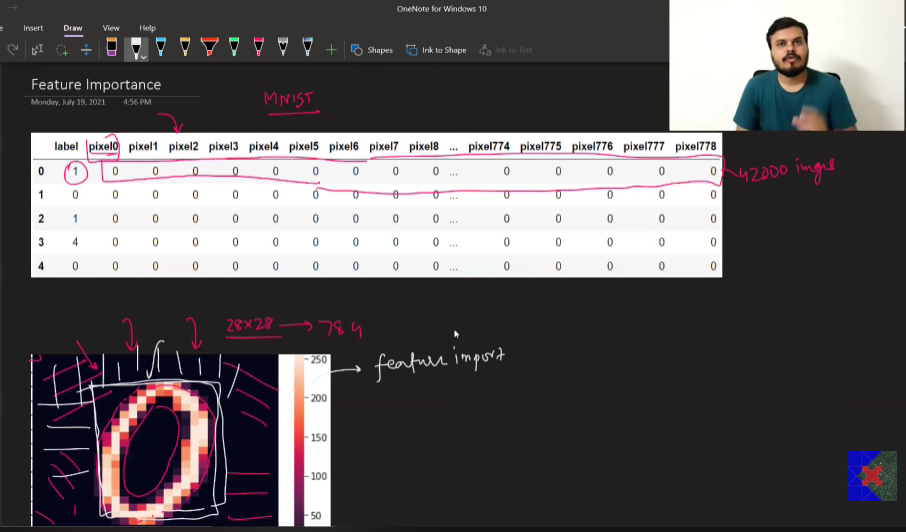

- For the above example of MNIST dataset, we can see that the most important features are the pixels in the center of the image, which makes sense because the digits are usually written in the center of the image. The less important features are the pixels in the corners of the image, which are usually blank.

- So algorithms like Random Forest, Gradient Boosting, etc. can detect the important features in the dataset and we can use that information to improve the performance of our model by selecting the most important features and dropping the less important features.

- Also, it gives us interpretability of the model, because we can see which features are important for the model to make predictions.


See code for feature importance using sklearn [here](7.2-Feature-importance-in-sklearn.ipynb)

# How is feature importance calculated?

- To know how feature importance is calculated in Random Forest, we need to understand it is calculated in Decision Tree first.

Run the [code](./7.3-How-feature-importance-is-calculated.ipynb) to see how feature importance is calculated in Decision Tree

- Formula to calculate feature importance in **Decision Tree** is:

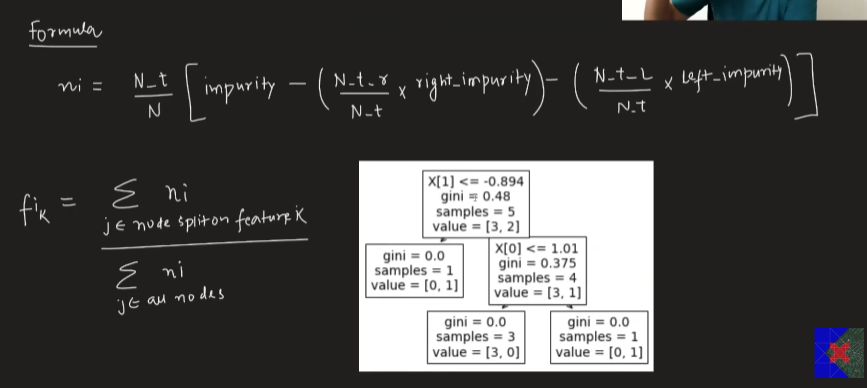
(You can see the above desicion tree in the pic in the code attached above)

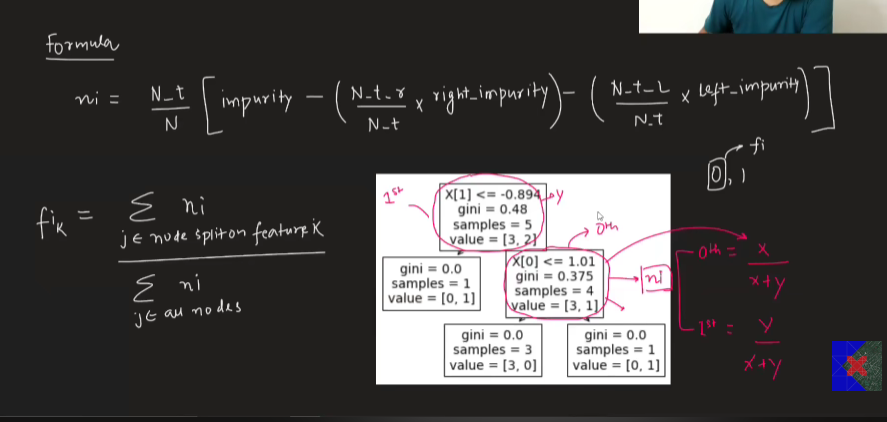

## Steps:
### 1. First find importance of all the nodes where **splits are made** in the tree using the formula below ($n_{i}$)


$$
n_i = \frac{N_t}{N} \left[ I(t) - \left(\frac{N_{t,R}}{N_t} \times I(t_R)\right) - \left(\frac{N_{t,L}}{N_t} \times I(t_L)\right) \right]
$$

Where:
- $N_t$ = Number of samples reaching the current node (Uss node k paas kitne rows hai)
- $N$ = Total number of samples in the dataset.
- $I(t)$ = Impurity (gini impurity) of the current node.
- $N_{t,R}$ = Number of samples reaching the right child.
- $N_{t,L}$ = Number of samples reaching the left child.
- $I(t_R)$ = Impurity of the right child.
- $I(t_L)$ = Impurity of the left child.



### 2. Then find importance of all the features in the tree using the formula below ($f_{i}$)


$$
f_i = \frac{\displaystyle\sum_{j \in N_i} n_j}
{\displaystyle\sum_{j=1}^{N} n_j}
$$

Where:
- $f_i$ = Importance of feature $i$.
- $N_i$ = Set of nodes where feature $i$ is used for splitting.
- $n_j$ = Importance of node $j$.
- $N$ = Total number of nodes in the decision tree.

This gives the normalized feature importance based on the number of samples at the nodes where the feature is used.



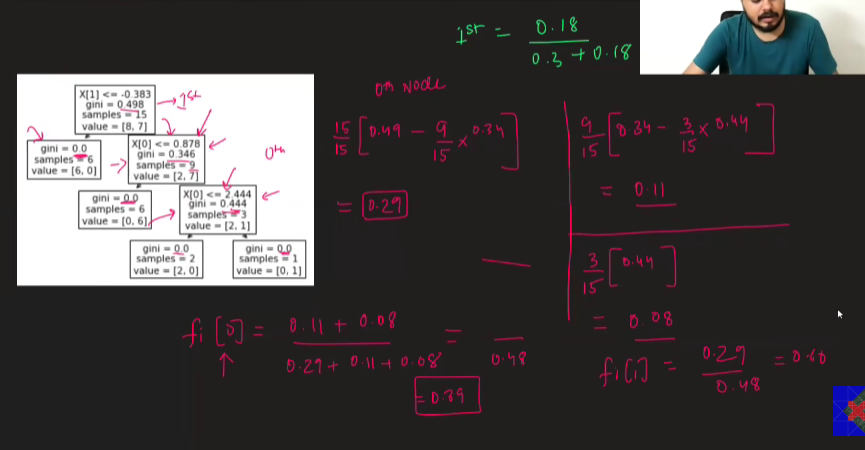

- You can see $n_{i}$ for each node where a split is made (3 nodes in this case) and then we can calculate $f_{i}$ for each feature (2 features in this case) 

### Feature importance calculation in Random Forest

- Now since random forest is made of multiple decision trees, we can calculate the feature importance of each feature from each decision tree and then take the average of all the feature importances to get the final feature importance of each feature in the random forest.

# <text style="color:red;"> WARNING</text>

- Imputity-based feature importance can be misleading for high-cardinality features.

- Cardinality means the number of unique (distinct) values in a feature or column.

- High-cardinality features are features that have a large number of unique values. For example, a feature that contains the names of all the cities in the world would be a high-cardinality feature.

- So, for high-cardinality features use **permutation_importance** instead of impurity-based feature importance.